In [1]:
import sys
sys.path.append('..')

from analysis.utils import get_runs_data, show_config_differences
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from IPython.display import display
import os

sns.set_style(style='darkgrid')
os.makedirs('figures', exist_ok=True)

In [8]:
def show_dataset_configurations(data) -> pd.DataFrame:
    cols = [
        'cfg.dataset.prefix_vocab_size',
        'cfg.dataset.prefix_length',
        'cfg.dataset.suffix_vocab_size',
        'cfg.dataset.suffix_length',
    ]
    df = data.groupby('_run_id')[cols].first()
    df.columns = df.columns.str.replace('cfg.dataset.', '')
    df['prefix_bits'] = df['prefix_length'] * np.log2(df['prefix_vocab_size'])
    df['suffix_bits'] = df['suffix_length'] * np.log2(df['suffix_vocab_size'])
    df['total_bits'] = df['prefix_bits'] + df['suffix_bits']
    df['total_length'] = df['prefix_length'] + df['suffix_length']
    df = df[[
        'prefix_vocab_size', 'prefix_length', 'prefix_bits',
        'suffix_vocab_size', 'suffix_length', 'suffix_bits',
        'total_length', 'total_bits',
    ]]
    df = df.sort_values('prefix_vocab_size').reset_index(drop=True)
    return df


def plot_metric(data, metric_name, ylabel, filename=None):
    plt.figure(figsize=(12, 6))
    groups = data.groupby('cfg.dataset.prefix_vocab_size')[[metric_name, 'train/global_step']]
    for vocab_size, group in groups:
        prefix_length = int(
            data[data['cfg.dataset.prefix_vocab_size'] == vocab_size]['cfg.dataset.prefix_length'].iloc[0]
        )
        steps = group['train/global_step'].tolist()
        values = group[metric_name].tolist()
        plt.plot(steps, values, label=f'V={int(vocab_size)}, L={prefix_length}', linewidth=2)
    plt.xlabel('Step', fontsize=20)
    plt.ylabel(ylabel, fontsize=20)
    plt.xticks(fontsize=16)
    plt.yticks(fontsize=16)
    plt.legend(
        loc='upper center',
        bbox_to_anchor=(0.5, -0.15),
        fontsize=16,
        ncol=3,
        frameon=True,
    )
    plt.tight_layout()
    if filename is None:
        filename = metric_name.replace('/', '_')
    plt.savefig(f'figures/{filename}.pdf', bbox_inches='tight')
    plt.show()

# Iso-Prefix-Information Experiment

Tests whether **prefix vocab size V** affects suffix memorization when **prefix information content is held exactly constant** at 240 bits.

Prefix length L is adjusted so that `L × log₂(V) = 240` for all conditions.
The suffix is identical across all runs: `vocab=128, length=50` (350 bits).
Only the suffix is trained — prefix labels are masked (`-100`).

| V    | L   | Prefix bits | Suffix bits | Total tokens |
|------|-----|-------------|-------------|---------------|
| 4    | 120 | 240         | 350         | 170           |
| 16   | 60  | 240         | 350         | 110           |
| 64   | 40  | 240         | 350         | 90            |
| 256  | 30  | 240         | 350         | 80            |
| 1024 | 24  | 240         | 350         | 74            |

**Question**: If memorization were governed by information content alone, all curves should overlap. A gap between curves implicates vocab size (disambiguating power) as an independent factor.

In [3]:
data = get_runs_data(
    tag='iso-prefix-info',
    project='memorization',
    metrics=[
        'train/exact_match_repeated',
        'train/loss_total',
        'train/loss_total_suffix',
        'train/loss_total_prefix',
    ],
)
show_config_differences(data)

Found 5 runs with tag 'iso-prefix-info'


,cfg.dataset.length,cfg.dataset.prefix_length,cfg.dataset.prefix_vocab_size
_run_id,,,
aa3z6h9p,110,60,16
eic9iflx,90,40,64
p1oskuqn,74,24,1024
quzjlmuu,170,120,4
u37b23xd,80,30,256


In [4]:
df = show_dataset_configurations(data)
display(df)

,prefix_vocab_size,prefix_length,prefix_bits,suffix_vocab_size,suffix_length,suffix_bits,total_length,total_bits
0,4,120,240.0,128,50,350.0,170,590.0
1,16,60,240.0,128,50,350.0,110,590.0
2,64,40,240.0,128,50,350.0,90,590.0
3,256,30,240.0,128,50,350.0,80,590.0
4,1024,24,240.0,128,50,350.0,74,590.0


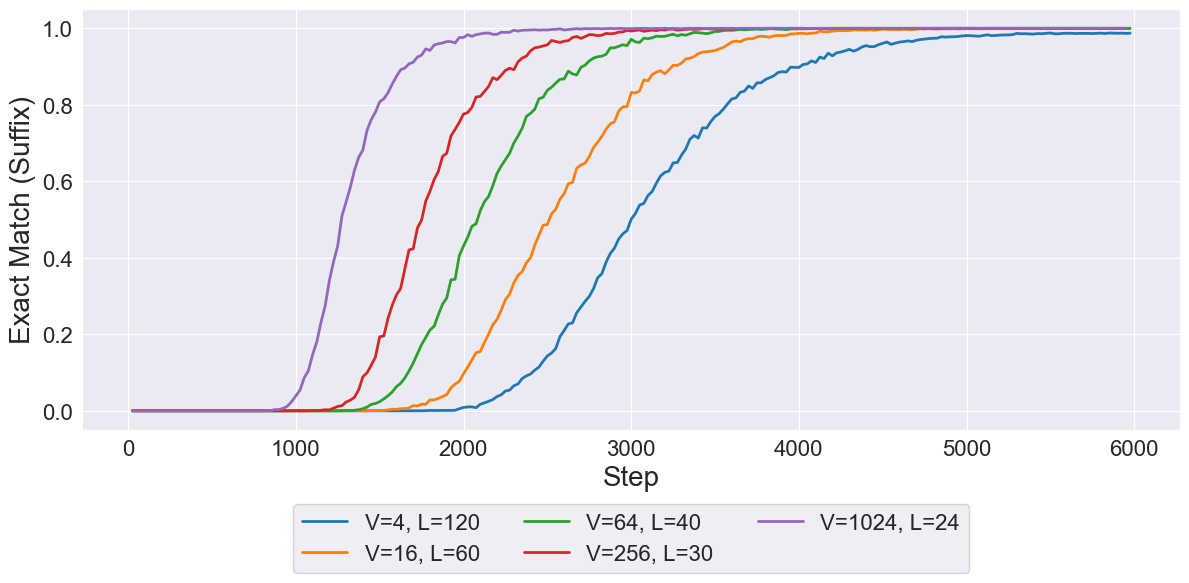

In [7]:
plot_metric(data, metric_name='train/exact_match_repeated', ylabel='Exact Match (Suffix)', filename='iso-prefix-em')

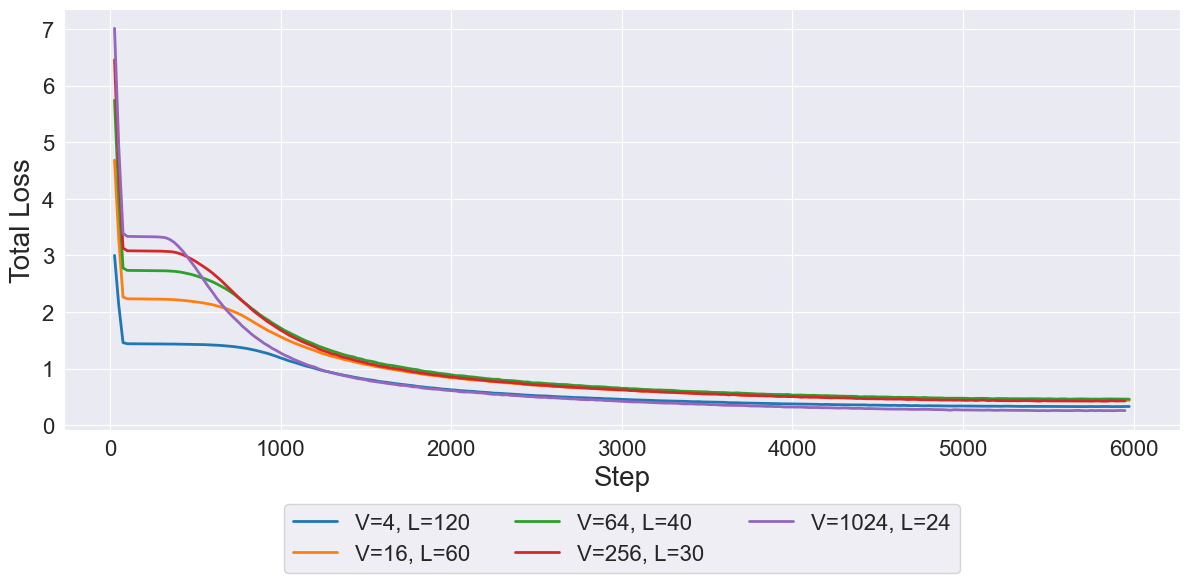

In [9]:
plot_metric(data, metric_name='train/loss_total', ylabel='Total Loss', filename="iso-prefix-loss")